[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch28_LabCh28_Variational_Autoencoder.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 28: Variational Autoencoders** (Part VI: Imagining).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=28](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=28)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch28 - Variational Autoencoders
## Turn an autoencoder into a generator by encoding clouds instead of points

This lab goes with **Chapter 28** of *The Why Book of Deep Learning*.

Chapter 27 ended on a problem: the latent space of a plain autoencoder has holes. Pick a random point, decode
it, and you usually get a smudge, because nothing forced the codes to fill the space. A **variational
autoencoder** (VAE) fixes this with two changes. The encoder outputs a small **cloud** (a mean and a
log-variance) instead of a single point, and a second loss term, the **KL divergence**, pulls every cloud
towards one shared shape: a standard normal centred on the origin. Then any point you sample from that
shape decodes to something digit-like.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Write a `Sampling` layer with the reparameterisation trick and check its gradients | Step 3 |
| Compute the Gaussian KL by hand and check it against a Monte Carlo estimate | Step 4 |
| Build a VAE with a 2-number latent space and count its 404,244 parameters by hand | Step 5 |
| Train it with a custom `train_step`: reconstruction + KL | Steps 6 and 7 |
| Compare its latent space with a plain autoencoder's | Steps 9 and 10 |
| Decode a grid of latent points, sample new digits, morph a 3 into an 8 | Steps 11 to 13 |
| Read the KL per latent dimension | Step 14 |
| Turn the β knob, and catch the "mean instead of sum" bug that silently sets β = 784 | Steps 15 and 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** a few minutes on a laptop CPU. We train on **20,000** of the 60,000 training digits for
> **10 epochs** per model, and the model is a small dense one. For a real run use all 60,000 digits and
> 30 to 50 epochs; the pictures get cleaner, but none of the lessons change.

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ops = keras.ops
keras.utils.set_random_seed(28)
np.set_printoptions(precision=4, suppress=True)
T0 = time.time()
print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)

TensorFlow: 2.21.0  Keras: 3.14.1


---
## Step 2 - Load MNIST, scale to [0, 1], flatten

The decoder ends in a **sigmoid** and the reconstruction loss is binary cross-entropy, so the pixels must lie
in [0, 1].

> **Predict:** the shape of the training array after flattening.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()
N_TRAIN = 20_000                                     # raise to 60_000 for a real run
x_train = x_train_full[:N_TRAIN].reshape(-1, 784).astype("float32") / 255.0
y_train = y_train_full[:N_TRAIN]
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0
print("train:", x_train.shape, " test:", x_test.shape, " range:", x_train.min(), "to", x_train.max())

train: (20000, 784)  test: (10000, 784)  range: 0.0 to 1.0


---
## Step 3 - The reparameterisation trick, on its own

The encoder will say "this digit lives in a cloud centred at `z_mean` with spread `exp(0.5 * z_log_var)`".
We need a point from that cloud. Drawing a random number is not something you can differentiate through, so
we draw the randomness **separately**, `eps` from a standard normal, and compute

`z = z_mean + exp(0.5 * z_log_var) * eps`

Now `z` is an ordinary function of `z_mean` and `z_log_var`, and gradients flow back into both.

> **Predict:** the gradient of `z` with respect to `z_mean` (it is a whole number), and with respect to
> `z_log_var` (it involves `eps`).

In [3]:
class Sampling(layers.Layer):
    """z = mean + std * eps, with eps ~ N(0, I) drawn outside the path of the gradient."""
    def __init__(self, seed=28, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(seed)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = keras.random.normal(shape=ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * eps

sampler = Sampling(seed=1)
m = tf.Variable([[0.5, -1.0]])
lv = tf.Variable([[0.0, np.log(0.25)]], dtype=tf.float32)   # variances 1 and 0.25, so std 1 and 0.5
with tf.GradientTape(persistent=True) as tape:
    z = sampler([m, lv])
    s = tf.reduce_sum(z)
eps = (z - m) / tf.exp(0.5 * lv)
print("z         :", z.numpy())
print("eps used  :", eps.numpy())
print("dz/dmean  :", tape.gradient(s, m).numpy())
print("dz/dlogvar:", tape.gradient(s, lv).numpy())
print("check 0.5*std*eps:", (0.5 * tf.exp(0.5 * lv) * eps).numpy())

z         : [[ 0.6267 -1.2465]]
eps used  : [[ 0.1267 -0.493 ]]
dz/dmean  : [[1. 1.]]
dz/dlogvar: [[ 0.0633 -0.1233]]
check 0.5*std*eps: [[ 0.0633 -0.1233]]


### Why we see this

`dz/dmean` is exactly 1: moving the centre of the cloud moves the sample by the same amount. `dz/dlogvar` is
`0.5 × std × eps`: widening the cloud pushes the sample further in whatever direction this particular `eps`
happened to point. Both are ordinary numbers, so backpropagation works. If we had written
`z = random.normal(mean, std)` directly, there would be no path from the loss back to the encoder at all.

---
## Step 4 - The KL term by hand

The KL divergence from a cloud `N(mu, sigma²)` to the standard normal `N(0, 1)` has a closed form, summed
over latent dimensions:

`KL = -0.5 * sum(1 + log_var - mu² - exp(log_var))`

Read it term by term: `mu²` charges for being far from the origin; `exp(log_var) - log_var - 1` charges for
a spread different from 1 (it is zero exactly when the variance is 1, and grows on both sides).

> **Predict:** the KL of a cloud that **is** the standard normal (`mu = 0`, `log_var = 0`). Then rank these
> three: a unit cloud moved to `mu = 2`; a cloud at the origin shrunk to std 0.1; a cloud at the origin
> blown up to std 3.

In [4]:
def kl_closed(mu, log_var):
    mu, log_var = np.asarray(mu, float), np.asarray(log_var, float)
    return -0.5 * np.sum(1 + log_var - mu**2 - np.exp(log_var))

def kl_monte_carlo(mu, sigma, n=400_000, rng=np.random.default_rng(0)):
    z = rng.normal(mu, sigma, n)                                   # samples from the cloud q
    log_q = -0.5 * ((z - mu) / sigma) ** 2 - np.log(sigma) - 0.5 * np.log(2 * np.pi)
    log_p = -0.5 * z**2 - 0.5 * np.log(2 * np.pi)                  # standard normal p
    return np.mean(log_q - log_p)

cases = [("standard normal", 0.0, 1.0), ("moved to mu = 2", 2.0, 1.0),
         ("shrunk to std 0.1", 0.0, 0.1), ("blown up to std 3", 0.0, 3.0)]
print(f"{'cloud':20s} {'closed form':>12s} {'Monte Carlo':>12s}")
for name, mu, sd in cases:
    print(f"{name:20s} {kl_closed([mu], [np.log(sd**2)]):12.4f} {kl_monte_carlo(mu, sd):12.4f}")

cloud                 closed form  Monte Carlo
standard normal           -0.0000       0.0000
moved to mu = 2            2.0000       2.0038
shrunk to std 0.1          1.8076       1.8081
blown up to std 3          2.9014       2.8905


### Why we see this

The standard normal costs nothing (0). A unit cloud moved to `mu = 2` costs `2² / 2 = 2` nats. Shrinking to a
std of 0.1 costs about 1.81, and blowing up to std 3 costs about 2.90. So the KL term **forbids both
extremes**: a cloud cannot collapse to a point (the plain autoencoder's habit) and cannot spread over
everything. The Monte Carlo column, which only uses the definition (the average of log q minus log p under
q), agrees with the formula to two or three decimals.

---
## Step 5 - Build the encoder and decoder, and count first

Encoder: 784 → Dense(256, relu) → two heads, `z_mean` (2 numbers) and `z_log_var` (2 numbers) → `Sampling`.
Decoder: 2 → Dense(256, relu) → Dense(784, sigmoid).

> **Predict:** the parameter count of each of the five Dense layers, and the total. Which layer is the
> smallest? Does `Sampling` have any parameters?

In [5]:
LATENT, HIDDEN = 2, 256
hand = {
    "enc_256":   (784 + 1) * HIDDEN,
    "z_mean":    (HIDDEN + 1) * LATENT,
    "z_log_var": (HIDDEN + 1) * LATENT,
    "dec_256":   (LATENT + 1) * HIDDEN,
    "out_784":   (HIDDEN + 1) * 784,
}
for k, v in hand.items():
    print(f"{k:10s} {v:>8,}")
HAND_TOTAL = sum(hand.values())
print(f"{'total':10s} {HAND_TOTAL:>8,}")

def make_encoder(name="encoder"):
    inp = layers.Input(shape=(784,))
    h = layers.Dense(HIDDEN, activation="relu", name="enc_256")(inp)
    z_mean = layers.Dense(LATENT, name="z_mean")(h)
    z_log_var = layers.Dense(LATENT, name="z_log_var")(h)
    z = Sampling(name="sampling")([z_mean, z_log_var])
    return keras.Model(inp, [z_mean, z_log_var, z], name=name)

def make_decoder(name="decoder"):
    inp = layers.Input(shape=(LATENT,))
    h = layers.Dense(HIDDEN, activation="relu", name="dec_256")(inp)
    out = layers.Dense(784, activation="sigmoid", name="out_784")(h)
    return keras.Model(inp, out, name=name)

encoder, decoder = make_encoder(), make_decoder()
encoder.summary()
decoder.summary()
zm, zlv, zz = encoder(x_train[:5])
print("z_mean", zm.shape, " z_log_var", zlv.shape, " z", zz.shape, " decoded", decoder(zz).shape)
assert encoder.count_params() + decoder.count_params() == HAND_TOTAL
if (LATENT, HIDDEN) == (2, 256):
    assert HAND_TOTAL == 404_244
print("hand count matches Keras:", encoder.count_params() + decoder.count_params())

enc_256     200,960
z_mean          514
z_log_var       514
dec_256         768
out_784     201,488
total       404,244


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_256 (Dense)     │ (None, 256)       │    200,960 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ enc_256[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ enc_256[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,988 (789.02 KB)

 Trainable params: 201,988 (789.02 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

 Total params: 202,256 (790.06 KB)

 Trainable params: 202,256 (790.06 KB)

 Non-trainable params: 0 (0.00 B)

z_mean (5, 2)  z_log_var (5, 2)  z (5, 2)  decoded (5, 784)
hand count matches Keras: 404244


### Why we see this

200,960 + 514 + 514 + 768 + 201,488 = **404,244**. The two heads cost 514 each: the whole "probabilistic" part
of the model is about a quarter of one percent of its parameters. The VAE is not a bigger network than an
autoencoder; it is the same network with a different job description. `Sampling` has 0 parameters: it only
does arithmetic with a random number.

---
## Step 6 - The VAE as a Keras model with its own `train_step`

The loss has two parts, both **per digit**, then averaged over the batch:

* **reconstruction**: binary cross-entropy **summed** over the 784 pixels (be faithful);
* **KL**: the closed form from Step 4, summed over the latent dimensions (be orderly).

`loss = reconstruction + beta * KL`. With `beta = 1` this is the standard VAE (the negative ELBO). The
argument `recon="mean"` lets us reproduce a common bug later (Step 16).

> **Predict:** at the very start, before any training, will the reconstruction term be near 0.69, near 70,
> or near 540? (A sigmoid that outputs 0.5 everywhere scores ln 2 ≈ 0.693 per pixel.)

In [6]:
def bce_per_pixel(x, x_hat):
    x_hat = ops.clip(x_hat, 1e-7, 1 - 1e-7)
    return -(x * ops.log(x_hat) + (1 - x) * ops.log(1 - x_hat))

def kl_per_digit(z_mean, z_log_var):
    return -0.5 * ops.sum(1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var), axis=1)

class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, recon="sum", **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta, self.recon = encoder, decoder, beta, recon
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon")
        self.kl_tracker = keras.metrics.Mean(name="kl")

    @property
    def metrics(self):
        return [self.loss_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, x):                                   # inference: decode the centre of the cloud
        return self.decoder(self.encoder(x)[0])

    def losses_for(self, x):
        z_mean, z_log_var, z = self.encoder(x)           # z is SAMPLED here, during training
        x_hat = self.decoder(z)
        per_pixel = bce_per_pixel(x, x_hat)
        recon = ops.sum(per_pixel, axis=1) if self.recon == "sum" else ops.mean(per_pixel, axis=1)
        kl = kl_per_digit(z_mean, z_log_var)
        return ops.mean(recon + self.beta * kl), ops.mean(recon), ops.mean(kl)

    def _update(self, total, recon, kl):
        self.loss_tracker.update_state(total)
        self.recon_tracker.update_state(recon)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            total, recon, kl = self.losses_for(x)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._update(total, recon, kl)

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        return self._update(*self.losses_for(x))

vae = VAE(encoder, decoder, beta=1.0)
t0, r0, k0 = vae.losses_for(x_test[:1000])
print(f"before training: recon {float(r0):.1f}  KL {float(k0):.3f}  total {float(t0):.1f}")
print(f"784 x ln 2 = {784 * np.log(2):.1f}")

before training: recon 543.7  KL 0.208  total 543.9
784 x ln 2 = 543.4


### Why we see this

A fresh decoder outputs roughly 0.5 for every pixel, so the summed reconstruction starts near
784 × ln 2 ≈ 543 nats. The KL starts tiny, because a fresh encoder outputs means and log-variances close to 0:
every cloud already looks like the standard normal. Training will **raise** the KL (the encoder must move the
clouds apart to say anything about the digit) while it lowers the reconstruction. Watch both.

---
## Step 7 - Train it

> **Predict:** after 10 epochs, will the KL end near 0, near 6, or near 60 nats per digit? (Hint: a 2-number
> code can only carry so much information.)

In [7]:
EPOCHS, BATCH = 10, 128

def train(model, epochs=EPOCHS, verbose=2):
    model.compile(optimizer=keras.optimizers.Adam(1e-3))
    t = time.time()
    h = model.fit(x_train, x_train, epochs=epochs, batch_size=BATCH,
                  validation_data=(x_test, x_test), verbose=verbose)
    print(f"trained in {time.time() - t:.0f}s")
    return h

hist = train(vae)
H = hist.history
print(f"test: recon {H['val_recon'][-1]:.1f}  KL {H['val_kl'][-1]:.2f}  total {H['val_loss'][-1]:.1f}")

Epoch 1/10


157/157 - 2s - 13ms/step - kl: 14.9103 - loss: 245.2191 - recon: 230.3089 - val_kl: 6.9079 - val_loss: 195.8714 - val_recon: 188.9636


Epoch 2/10


157/157 - 1s - 5ms/step - kl: 5.9196 - loss: 190.1060 - recon: 184.1865 - val_kl: 5.6368 - val_loss: 184.9008 - val_recon: 179.2641


Epoch 3/10


157/157 - 1s - 5ms/step - kl: 5.2237 - loss: 182.1611 - recon: 176.9375 - val_kl: 5.1467 - val_loss: 177.7890 - val_recon: 172.6423


... (11 outputs left out)

157/157 - 1s - 5ms/step - kl: 4.9517 - loss: 166.9572 - recon: 162.0055 - val_kl: 4.9368 - val_loss: 166.8095 - val_recon: 161.8726


Epoch 10/10


157/157 - 1s - 5ms/step - kl: 4.9604 - loss: 166.1686 - recon: 161.2082 - val_kl: 4.9656 - val_loss: 166.0857 - val_recon: 161.1201


trained in 10s
test: recon 161.1  KL 4.97  total 166.1


### Why we see this

Reconstruction falls from about 543 to about 160 nats per digit, and the KL settles at about 5 nats (it
overshoots to about 15 in the first epoch, then the model tidies up). The KL is the price the model pays for its code: each nat is information about the digit
squeezed through the 2-number bottleneck. It cannot go far, because two noisy numbers can only tell the
decoder so much. That is also why the reconstructions in the next step are blurry.

---
## Step 8 - Reconstructions

Top: test digits. Middle: decoded from the **mean** `z_mean` (what you use at inference). Bottom: decoded from
a **sampled** `z` (what training sees).

> **Predict:** which row will look sharper, the mean row or the sampled row?

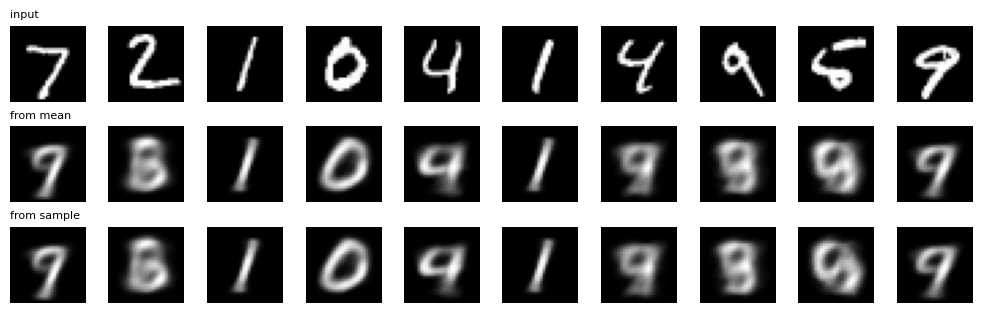

std of each cloud (first 3 digits): [[0.1949 0.225 ]
 [0.0651 0.0615]
 [0.1764 0.3048]]


In [8]:
idx = np.arange(10)
zm, zlv, zs = encoder.predict(x_test[idx], verbose=0)
rows = [x_test[idx], decoder.predict(zm, verbose=0), decoder.predict(zs, verbose=0)]
fig, ax = plt.subplots(3, 10, figsize=(10, 3.2))
for r, (imgs, title) in enumerate(zip(rows, ["input", "from mean", "from sample"])):
    for c in range(10):
        ax[r, c].imshow(imgs[c].reshape(28, 28), cmap="gray"); ax[r, c].axis("off")
    ax[r, 0].set_title(title, fontsize=8, loc="left")
plt.tight_layout(); plt.show()
print("std of each cloud (first 3 digits):", np.exp(0.5 * zlv[:3]))

### Why we see this

Both rows are blurry: with only two numbers the decoder learns an "average" digit for each region of the
latent space. The sampled row is sometimes a slightly different digit, because the sample landed nearer a
neighbouring cloud. Each cloud's standard deviation is well below 1 (the printout), so the clouds are small,
but not points: that is the KL term at work.

---
## Step 9 - A plain autoencoder with the same body, for comparison

Same layers, same 2-number middle, but the code is a single point and the loss is reconstruction only. This is
Chapter 27's model in miniature.

> **Predict:** its reconstruction loss will be lower or higher than the VAE's? Why?

In [9]:
ae_in = layers.Input(shape=(784,))
ae_code = layers.Dense(LATENT, name="code")(layers.Dense(HIDDEN, activation="relu")(ae_in))
ae_dec = make_decoder("ae_decoder")
ae = keras.Model(ae_in, ae_dec(ae_code), name="plain_ae")
ae_encoder = keras.Model(ae_in, ae_code)
print("plain AE parameters:", f"{ae.count_params():,}", " (VAE minus one 514-parameter head:", f"{HAND_TOTAL - 514:,})")
assert ae.count_params() == HAND_TOTAL - 514

def summed_bce(x, x_hat):
    return ops.sum(bce_per_pixel(x, x_hat), axis=1)

ae.compile(optimizer=keras.optimizers.Adam(1e-3), loss=summed_bce)
t = time.time()
h_ae = ae.fit(x_train, x_train, epochs=EPOCHS, batch_size=BATCH, validation_data=(x_test, x_test), verbose=0)
print(f"trained in {time.time() - t:.0f}s;  plain AE test recon {h_ae.history['val_loss'][-1]:.1f}"
      f"   vs VAE {H['val_recon'][-1]:.1f}")

plain AE parameters: 403,730  (VAE minus one 514-parameter head: 403,730)


trained in 9s;  plain AE test recon 155.6   vs VAE 161.1


### Why we see this

The plain autoencoder reconstructs **better**: it is allowed to put each digit at an exact point anywhere it
likes, and the decoder never has to cope with noise in the code. The VAE gives up some faithfulness to buy
order. The next step shows what the order looks like.

---
## Step 10 - The two latent spaces, side by side

Each dot is a test digit placed at its code (the plain AE's code; the VAE's `z_mean`), coloured by its label.

> **Predict:** which plot will be centred on (0, 0) with a roughly round outline, and which will have long
> arms, odd scales and empty gaps?

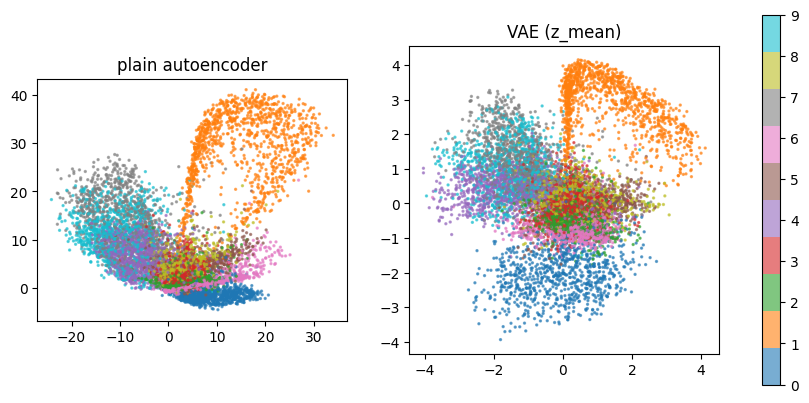

plain AE  mean [1.7929 7.6622]  std [9.2715 9.6197]  range x [-24.1, 34.0] y [-4.4, 41.0]
VAE       mean [-0.1202  0.3086]  std [1.2553 1.3635]  range x [-4.0, 4.1] y [-3.9, 4.2]


In [10]:
z_ae = ae_encoder.predict(x_test, verbose=0)
z_vae = encoder.predict(x_test, verbose=0)[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a, z, title in [(ax[0], z_ae, "plain autoencoder"), (ax[1], z_vae, "VAE (z_mean)")]:
    sc = a.scatter(z[:, 0], z[:, 1], c=y_test, cmap="tab10", s=2, alpha=0.6)
    a.set_title(title); a.set_aspect("equal")
fig.colorbar(sc, ax=ax, ticks=range(10))
plt.show()
for name, z in [("plain AE", z_ae), ("VAE", z_vae)]:
    print(f"{name:9s} mean {z.mean(0)}  std {z.std(0)}  range x [{z[:,0].min():.1f}, {z[:,0].max():.1f}]"
          f" y [{z[:,1].min():.1f}, {z[:,1].max():.1f}]")

### Why we see this

The plain autoencoder's codes sit wherever the optimiser happened to push them: off-centre, on arbitrary
scales, in streaks with gaps between them. Nothing in its loss cares. The VAE's means are packed round the
origin with a spread close to 1, because the KL term charges for every cloud that wanders off or shrinks.
The classes still form regions (the decoder needs them to), but the regions **touch**.

---
## Step 11 - Decode a grid of latent points: the map of all digits

Walk a 15 × 15 grid of points from -2.5 to +2.5 on both axes and decode each one.

> **Predict:** will neighbouring cells show the same digit, a gradual change, or random jumps? Will any cell
> be pure noise?

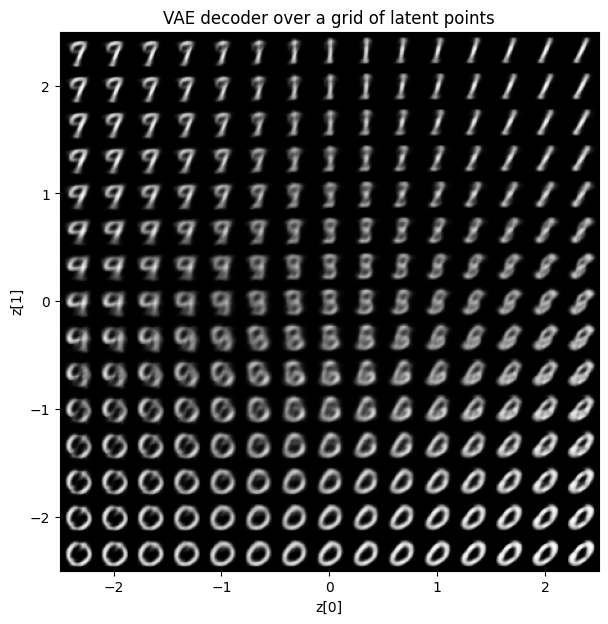

In [11]:
n, lim = 15, 2.5
g = np.linspace(-lim, lim, n)
grid_z = np.array([[xv, yv] for yv in g[::-1] for xv in g], dtype="float32")
imgs = decoder.predict(grid_z, verbose=0).reshape(n, n, 28, 28)
canvas = imgs.transpose(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap="gray", extent=[-lim, lim, -lim, lim])
plt.title("VAE decoder over a grid of latent points"); plt.xlabel("z[0]"); plt.ylabel("z[1]"); plt.show()

### Why we see this

Every cell is a recognisable digit or a believable blend of two, and the digits morph gradually as you
move (in our run; yours may be rotated or mirrored): walking down the left edge, a 7 bends into a 9, then a 6, then a 0; 1s lean across the top right; the
crowded middle holds blurry 3s, 5s and 8s. That is **continuity** (nearby codes decode to similar
images) and **completeness** (no holes). Both come from the overlapping clouds: during training the decoder
saw samples from everywhere in this square, so it had to make sense of everywhere.

---
## Step 12 - Sample new digits from the prior, and do the same for the plain AE

Draw 16 points from the standard normal and decode them. For the plain AE, draw 16 points uniformly from the
box that holds its codes.

> **Predict:** which set will look more like real digits?

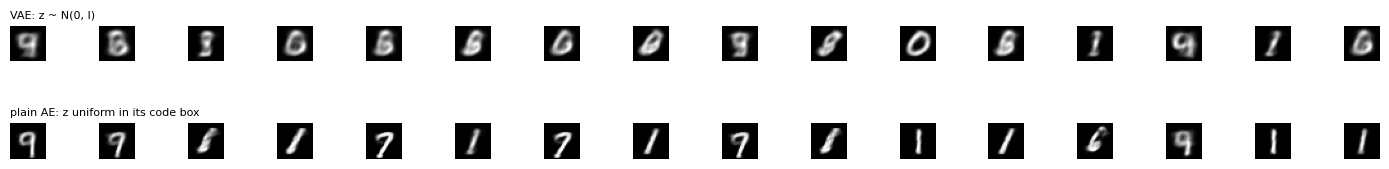

In [12]:
rng = np.random.default_rng(28)
z_prior = rng.standard_normal((16, LATENT)).astype("float32")
lo, hi = z_ae.min(0), z_ae.max(0)
z_box = (lo + (hi - lo) * rng.random((16, LATENT))).astype("float32")
sets = [(decoder.predict(z_prior, verbose=0), "VAE: z ~ N(0, I)"),
        (ae_dec.predict(z_box, verbose=0), "plain AE: z uniform in its code box")]
fig, ax = plt.subplots(2, 16, figsize=(14, 2.2))
for r, (imgs, title) in enumerate(sets):
    for c in range(16):
        ax[r, c].imshow(imgs[c].reshape(28, 28), cmap="gray"); ax[r, c].axis("off")
    ax[r, 0].set_title(title, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### Why we see this

The VAE row is a varied set of new, blurry but plausible digits: the prior is exactly the region the decoder
was trained to cover, and every digit owns a share of it. The plain AE row is lopsided: its code box is mostly
empty space round one long arm of the scatter (Step 10), and the decoder fills that space with the same few
shapes (often 1s and 7s) or odd strokes. You cannot choose "where to sample" for a plain autoencoder, because
nothing says where its digits live. With a 32-number code (Chapter 27) the problem is far worse: almost
every random point falls in a hole.

---
## Step 13 - Morph a 7 into a 0

Take the average `z_mean` of all test 7s and of all test 0s (the centre of each digit's region), walk in 10
equal steps from one to the other, and decode.

> **Predict:** will the middle images be a smudge, a 7 and a 0 superimposed, or other digits "between" them?

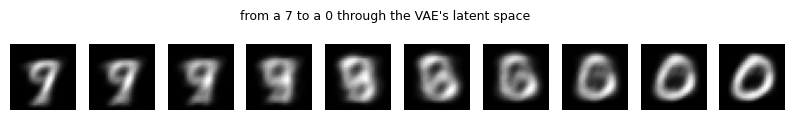

start [-1.2076  1.2532]  end [-0.0399 -1.8967]  distance 3.36


In [13]:
a, b = z_vae[y_test == 7].mean(0), z_vae[y_test == 0].mean(0)
path = np.array([a + t * (b - a) for t in np.linspace(0, 1, 10)], dtype="float32")
imgs = decoder.predict(path, verbose=0)
fig, ax = plt.subplots(1, 10, figsize=(10, 1.4))
for c in range(10):
    ax[c].imshow(imgs[c].reshape(28, 28), cmap="gray"); ax[c].axis("off")
plt.suptitle("from a 7 to a 0 through the VAE's latent space", fontsize=9); plt.show()
print("start", a, " end", b, " distance", np.linalg.norm(b - a).round(2))

### Why we see this

The path stays on "digit land" the whole way: the strokes bend and close rather than fading one picture out
and the other in. If the straight line crosses a third digit's region, the walk passes through that digit
(in our run a 9, a blurry 8 and a 6), which is honest: the line is the shortest way across the map, not
the shortest way through "meaning". Try a 3 and an 8 as well: with only two latent numbers, 3s, 5s and 8s
share the crowded middle of the map, and their decodes are blurred together.

---
## Step 14 - Read the KL per latent dimension

The total KL hides a useful detail: how much **each** latent number is used. A dimension whose KL is about 0
has every cloud sitting on the standard normal: it carries no information, and the decoder has learnt to
ignore it. This is what **posterior collapse** looks like from the inside.

> **Predict:** in a 2-D VAE on MNIST, will both dimensions be in use?

In [14]:
def kl_report(enc, x=x_test, label=""):
    zm, zlv, _ = enc.predict(x, verbose=0)
    per_dim = (-0.5 * (1 + zlv - zm**2 - np.exp(zlv))).mean(0)
    print(f"{label:22s} KL per dim {np.round(per_dim, 3)}  total {per_dim.sum():.3f}")
    return per_dim

_ = kl_report(encoder, label="VAE beta=1")

VAE beta=1             KL per dim [2.312 2.643]  total 4.955


### Why we see this

Both dimensions carry a few nats. With only two numbers available the model needs both. In a VAE with, say,
32 latent dimensions you would typically see some dimensions near 0: they are switched off. A few unused
dimensions are normal; **all** of them near 0 is collapse.

---
## Step 15 - Turn the β knob: 0.1, 1 and 4

`loss = reconstruction + beta * KL`. A small β cares mostly about faithfulness; a large β cares mostly about
order. We reuse the β = 1 model and train two more with the same budget.

> **Predict:** as β goes 0.1 → 1 → 4, which way does the reconstruction term move, and which way the KL?
> Which β will give the latent scatter that looks most like the plain autoencoder's?

trained in 10s


trained in 10s
 beta    recon      KL
  0.1    155.9   16.55
  1.0    161.1    4.97
  4.0    166.9    2.87


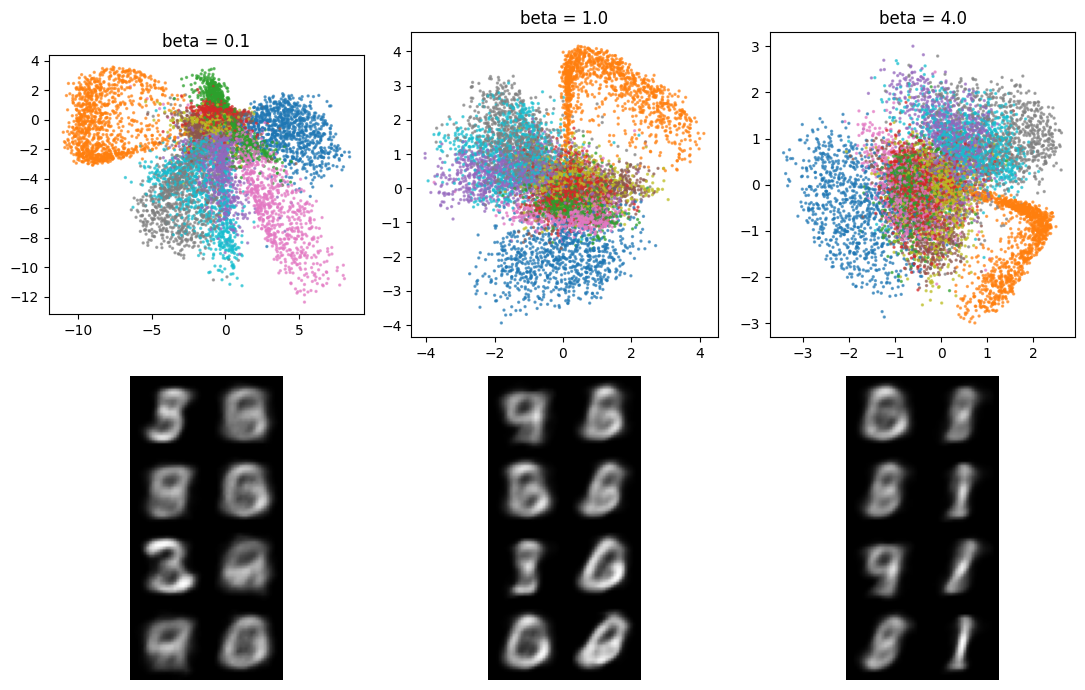

In [15]:
results = {1.0: (vae, H)}
for beta in [0.1, 4.0]:
    m_ = VAE(make_encoder(f"enc_b{beta}"), make_decoder(f"dec_b{beta}"), beta=beta)
    results[beta] = (m_, train(m_, verbose=0).history)
print(f"{'beta':>5s} {'recon':>8s} {'KL':>7s}")
for beta in sorted(results):
    Hb = results[beta][1]
    print(f"{beta:5.1f} {Hb['val_recon'][-1]:8.1f} {Hb['val_kl'][-1]:7.2f}")
fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for c, beta in enumerate(sorted(results)):
    mb = results[beta][0]
    zb = mb.encoder.predict(x_test, verbose=0)[0]
    ax[0, c].scatter(zb[:, 0], zb[:, 1], c=y_test, cmap="tab10", s=2, alpha=0.6)
    ax[0, c].set_title(f"beta = {beta}"); ax[0, c].set_aspect("equal")
    smp = mb.decoder.predict(z_prior[:8], verbose=0).reshape(8, 28, 28)
    ax[1, c].imshow(np.hstack([np.vstack(smp[:4]), np.vstack(smp[4:])]), cmap="gray"); ax[1, c].axis("off")
plt.tight_layout(); plt.show()

### Why we see this

Raising β trades faithfulness for order: reconstruction gets worse, KL gets smaller (in our run: recon
155.9, 161.1, 166.9 and KL 16.6, 5.0, 2.9 nats for β = 0.1, 1, 4). At β = 0.1 the clouds
are allowed to shrink and spread out: the scatter starts to look like the plain autoencoder's, and samples from
the prior include more off-map smudges. At β = 4 the clouds are pushed hard onto the standard normal: the map
is very orderly and the digits are blurrier and less distinct. β > 1 is the **β-VAE**: some of that extra
pressure tends to make individual latent axes line up with separate factors (slant, thickness), which is
called disentanglement. It is a tendency, not a guarantee.

---
## Step 16 - The silent bug: averaging the reconstruction over pixels

Many first VAEs use `keras.losses.binary_crossentropy`, which **averages** over the 784 pixels, and then add
the KL **summed** over the latent dimensions. Compare:

* correct: `sum_bce + KL`
* bug: `mean_bce + KL` = `(sum_bce + 784 * KL) / 784`

Dividing a loss by a constant only rescales it, so the bug is the same as training the correct loss with
**β = 784**.

> **Predict:** the KL at the end of training. What will 16 samples from the prior look like?

trained in 11s


mean-recon model: KL 0.0001   summed recon (decoded from z_mean) 206.1


VAE recon=mean         KL per dim [0. 0.]  total 0.000


VAE recon=sum          KL per dim [2.312 2.643]  total 4.955


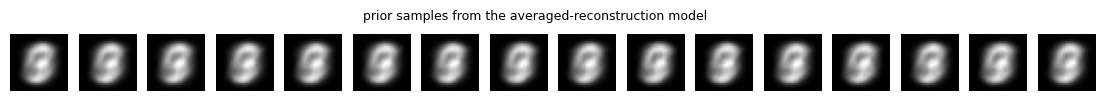

pixel spread across the 16 samples: 0.0034


In [16]:
vae_mean = VAE(make_encoder("enc_mean"), make_decoder("dec_mean"), beta=1.0, recon="mean")
h_mean = train(vae_mean, verbose=0).history
zm_, zlv_, _ = vae_mean.encoder.predict(x_test, verbose=0)
sum_recon = float(ops.mean(summed_bce(x_test, vae_mean.predict(x_test, verbose=0))))
print(f"mean-recon model: KL {h_mean['val_kl'][-1]:.4f}   summed recon (decoded from z_mean) {sum_recon:.1f}")
kl_report(vae_mean.encoder, label="VAE recon=mean")
kl_report(encoder, label="VAE recon=sum")
smp = vae_mean.decoder.predict(z_prior, verbose=0)
fig, ax = plt.subplots(1, 16, figsize=(14, 1.1))
for c in range(16):
    ax[c].imshow(smp[c].reshape(28, 28), cmap="gray"); ax[c].axis("off")
plt.suptitle("prior samples from the averaged-reconstruction model", fontsize=9); plt.show()
print("pixel spread across the 16 samples:", round(float(smp.std(0).mean()), 4))

### Why we see this

The KL is pushed almost to zero (0.0001 nats in our run): every digit's cloud is the standard normal, so the code says nothing about
the digit, and the decoder learns the only safe answer: the **average digit**, a blurry blob that looks the
same whatever you feed it. All 16 samples are nearly identical (tiny pixel spread). This is posterior
collapse caused by a reduction, not by the architecture, and nothing crashes: the loss curve looks smooth and
low. **Sum the reconstruction over pixels, or average both terms the same way, and print the KL.**

---
## Step 17 - Sample or mean? Three passes over the same digit

`encoder(x)` returns a fresh sample each call. Decode the same test digit three times from samples, then once
from the mean.

> **Predict:** will the three sampled decodes be identical?

pixel difference between sample 1 and sample 2: 0.0103


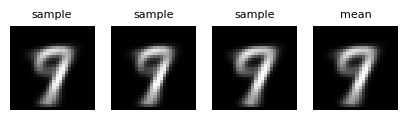

whole lab so far: 60s


In [17]:
x1 = x_test[:1]
outs = [decoder.predict(encoder.predict(x1, verbose=0)[2], verbose=0) for _ in range(3)]
outs.append(decoder.predict(encoder.predict(x1, verbose=0)[0], verbose=0))
print("pixel difference between sample 1 and sample 2:", round(float(np.abs(outs[0] - outs[1]).mean()), 4))
fig, ax = plt.subplots(1, 4, figsize=(5, 1.5))
for c, (o, t) in enumerate(zip(outs, ["sample", "sample", "sample", "mean"])):
    ax[c].imshow(o.reshape(28, 28), cmap="gray"); ax[c].axis("off"); ax[c].set_title(t, fontsize=8)
plt.show()
print(f"whole lab so far: {time.time() - T0:.0f}s")

### Why we see this

The sampled decodes differ a little: the sampling layer is live whenever you call the encoder. That is what
you want while **training** (it is what fills the holes) and usually **not** what you want when you need a
repeatable answer (use `z_mean`). To **generate**, skip the encoder entirely and sample `z` from the prior.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | `LATENT = 8` (keep β = 1); rerun from Step 5, skipping the 2-D pictures of Steps 10, 11 and 13 | lower recon, higher total KL; some dims near 0? | |
| 2 | β = 0 (pure reconstruction, sampling still on) | the clouds shrink to points; KL climbs; samples get worse | |
| 3 | Remove `Sampling` (use `z_mean` as `z`) but keep the KL | the KL now only pulls the means; is the space still hole-free? | |
| 4 | KL warm-up: β rises from 0 to 1 over the first 5 epochs | early epochs reconstruct well; final KL a little higher | |
| 5 | Predict σ directly with `Dense(2, activation=None)` and `std = sigma` | negative std: what goes wrong in `log`? | |
| 6 | `recon="mean"` but β = 1/784 | identical to the correct model up to a scale of the loss | |
| 7 | Train on 60,000 digits for 30 epochs | sharper grid, same lessons | |

## Exercises

1. Write the KL warm-up of Trial 4 as a Keras callback that sets `model.beta` at the start of each epoch.
   (Store β in a variable the `train_step` reads, so that changing it takes effect.)
2. Make a **conditional VAE**: concatenate a one-hot label to the encoder input and to `z` before the decoder.
   Then fix the label at 7 and decode the grid of Step 11. What do the two latent axes control now?
3. Use the VAE for anomaly detection: train without the digit 5, then compare the loss (reconstruction + KL)
   of test 5s against the others. Is it better than reconstruction alone?
4. Replace the dense layers with a small convolutional encoder and decoder (Chapter 27, Step 10). Count the
   parameters first. Does the grid get sharper?
5. The loss printed by Keras is the negative ELBO per digit. Compare it between β = 1 and the
   averaged-reconstruction model. Why is that comparison meaningless?

## Cheat sheet

| Idea | One line |
|---|---|
| Encoder heads | `z_mean`, `z_log_var`: the centre and (log) size of a cloud per input |
| Why log-variance | any real number is valid; `exp` makes it positive |
| Reparameterisation | `z = z_mean + exp(0.5 * z_log_var) * eps`, `eps ~ N(0, I)` |
| KL to N(0, I) | `-0.5 * sum(1 + log_var - mu**2 - exp(log_var))`, per digit |
| Loss | summed reconstruction + β × KL, averaged over the batch |
| β | small: faithful, holey; large: orderly, blurry; 784 by accident if you average the pixels |
| Collapse | KL ≈ 0 for every dimension, all samples alike |
| Inference | reconstruct from `z_mean`; generate by sampling `z ~ N(0, I)` and decoding |